## 1. Setup and load data
In a local virtual environment, install `pandas numpy scikit-learn matplotlib seaborn jupyter joblib`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
data = fetch_california_housing(as_frame=True)
df = data.frame.copy()
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Exploratory data analysis
Check data types, missing values, summary statistics, distributions and linear correlations. Correlation is not causation.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
Missing values by column:


,Missing
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.0,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.0,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.0,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.0,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.0,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.0,2.069,1.154,0.150,1.196,1.797,2.647,5.000


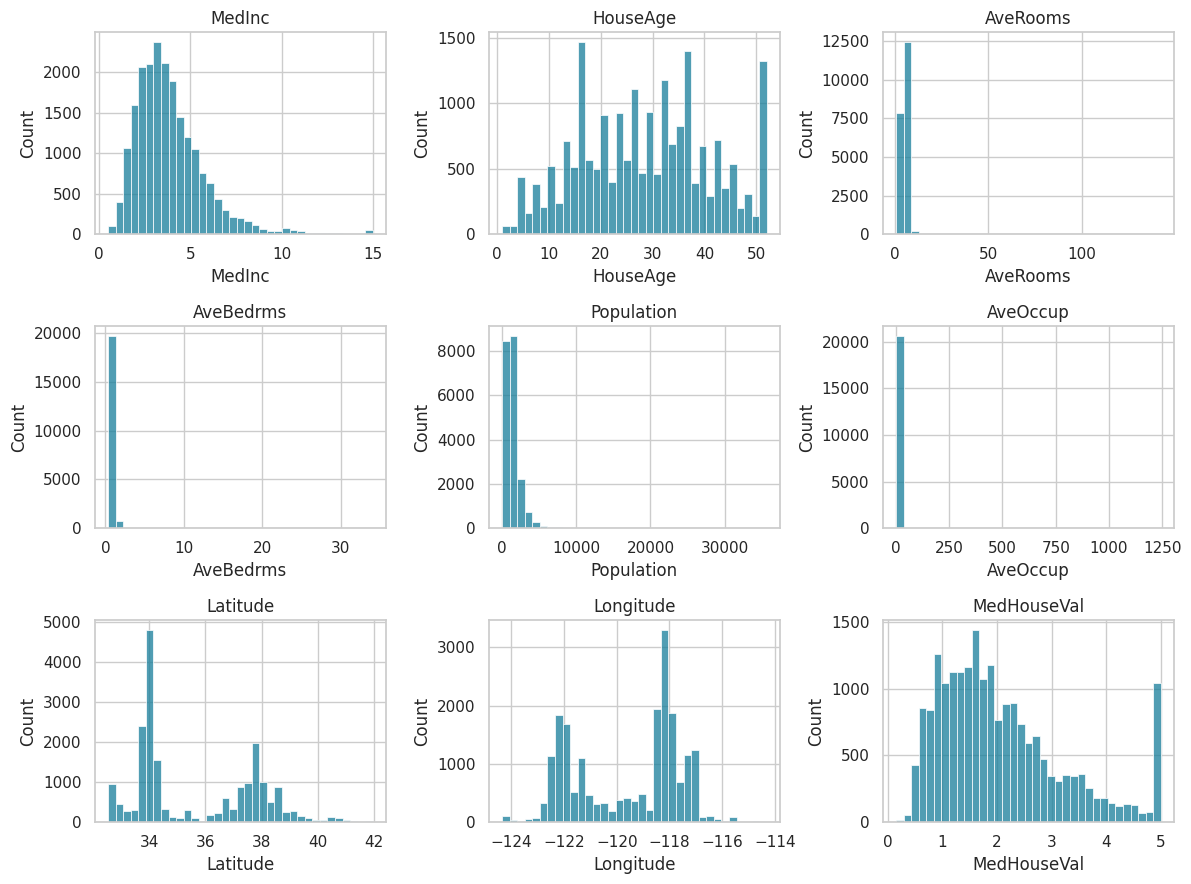

In [2]:
df.info()
missing = df.isna().sum()
print("Missing values by column:")
display(missing.to_frame("Missing"))
print("Duplicate rows:", df.duplicated().sum())
display(df.describe().T.round(3))
fig_dist, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], bins=35, ax=ax, color="#167D9A")
    ax.set_title(col)
fig_dist.tight_layout()
plt.show()

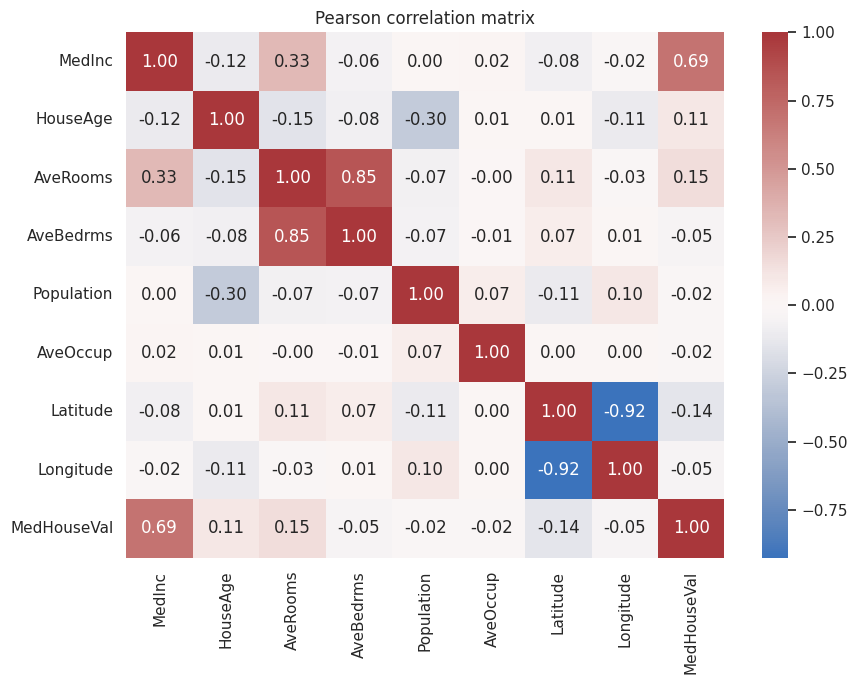

Target correlations:


,MedHouseVal
MedInc,0.688075
AveRooms,0.151948
Latitude,-0.144160
HouseAge,0.105623
AveBedrms,-0.046701
Longitude,-0.045967
Population,-0.024650
AveOccup,-0.023737


In [3]:
corr = df.corr(numeric_only=True)
fig_corr, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Pearson correlation matrix")
fig_corr.tight_layout()
plt.show()
print("Target correlations:")
display(corr["MedHouseVal"].drop("MedHouseVal").sort_values(key=abs, ascending=False))

## 3. Preprocessing and split
Use all eight numeric predictors and an 80/20 reproducible split. Median imputation is fitted only on training data to prevent leakage. it has no effect when predictors contain no missing values. Ordinary least squares does not require feature scaling for prediction.

In [4]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 16512 | Test rows: 4128


## 4. Train linear regression
The model estimates an intercept and one coefficient per feature by minimizing squared training residuals. A mean-prediction baseline provides context.

In [5]:
model = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
base_pred = baseline.predict(X_test)
coefficients = pd.Series(model.named_steps["linearregression"].coef_, index=X.columns, name="Coefficient")
display(coefficients.to_frame())

,Coefficient
MedInc,0.448675
HouseAge,0.009724
AveRooms,-0.123323
AveBedrms,0.783145
Population,-0.000002
AveOccup,-0.003526
Latitude,-0.419792
Longitude,-0.433708


## 5. Evaluation
MAE is the mean absolute error; RMSE penalizes larger errors more heavily; R² measures improvement in squared error relative to predicting the test-set mean. Lower MAE/RMSE and higher R² are better.

In [6]:
def evaluate(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted)}
metrics = pd.DataFrame({"Linear regression": evaluate(y_test, y_pred),
                        "Mean baseline": evaluate(y_test, base_pred)}).T
display(metrics.round(4))
mae, rmse, r2 = metrics.loc["Linear regression", ["MAE", "RMSE", "R2"]]
print(f"MAE: ${mae*100000:,.0f} | RMSE: ${rmse*100000:,.0f} | R²: {r2:.4f}")

,MAE,RMSE,R2
Linear regression,0.5332,0.7456,0.5758
Mean baseline,0.9061,1.1449,-0.0002


MAE: $53,320 | RMSE: $74,558 | R²: 0.5758


## 6. Diagnostic plots
Points near the diagonal indicate close predictions. Residuals are actual minus predicted. systematic patterns may indicate nonlinearity, unequal error variance or the effect of capped target values.

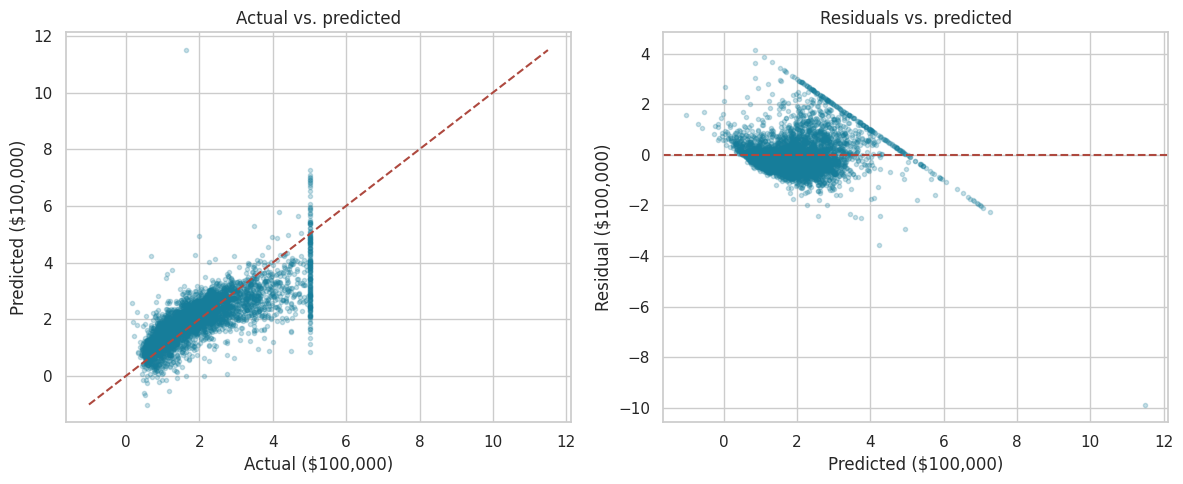

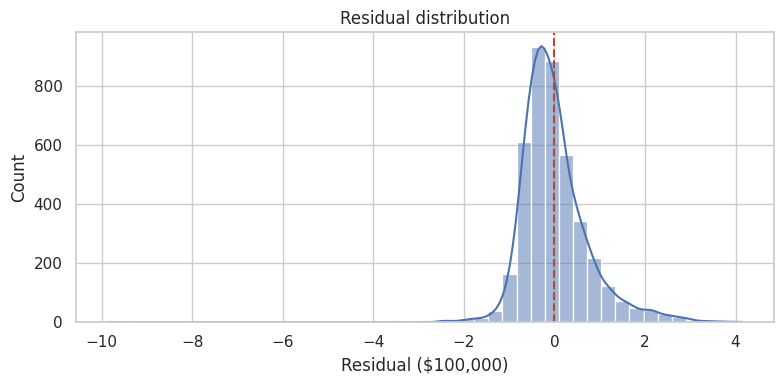

In [7]:
residuals = y_test.to_numpy() - y_pred
fig_diag, axes = plt.subplots(1, 2, figsize=(12, 5))
lo = min(y_test.min(), y_pred.min()); hi = max(y_test.max(), y_pred.max())
axes[0].scatter(y_test, y_pred, alpha=.24, s=9, color="#167D9A")
axes[0].plot([lo, hi], [lo, hi], "--", color="#AE493F")
axes[0].set(xlabel="Actual ($100,000)", ylabel="Predicted ($100,000)", title="Actual vs. predicted")
axes[1].scatter(y_pred, residuals, alpha=.24, s=9, color="#167D9A")
axes[1].axhline(0, color="#AE493F", linestyle="--")
axes[1].set(xlabel="Predicted ($100,000)", ylabel="Residual ($100,000)", title="Residuals vs. predicted")
fig_diag.tight_layout()
plt.show()
fig_res, ax = plt.subplots(figsize=(8, 4))
sns.histplot(residuals, bins=45, kde=True, ax=ax)
ax.axvline(0, color="#AE493F", linestyle="--")
ax.set(xlabel="Residual ($100,000)", title="Residual distribution")
fig_res.tight_layout()
plt.show()

## 7. Findings and improvement ideas
The following cell reports findings calculated from the data. Potential improvements include nonlinear models (random forests or gradient boosting), geographic feature engineering, and cross-validation with geographic grouping. The historical, aggregated and capped target limits real-world applicability. A random split may overstate generalization to unseen regions.

In [8]:
target_corr = corr["MedHouseVal"].drop("MedHouseVal")
strongest = target_corr.abs().idxmax()
print(f"Strongest absolute target correlation: {strongest} ({target_corr[strongest]:.3f})")
print(f"Test R²: {r2:.3f}; mean baseline R²: {metrics.loc['Mean baseline','R2']:.3f}")
print(f"Negative predictions: {(y_pred < 0).sum()}; target maximum: {y.max():.5f}")
joblib.dump(model, "house_price_model.joblib")

Strongest absolute target correlation: MedInc (0.688)
Test R²: 0.576; mean baseline R²: -0.000
Negative predictions: 15; target maximum: 5.00001


['house_price_model.joblib']

In [9]:
from textwrap import fill

def slide(title, subtitle, number):
    fig = plt.figure(figsize=(12, 6.75), facecolor="#F7FAFC")
    fig.text(.06, .91, title, fontsize=25, weight="bold", color="#123047")
    fig.text(.06, .855, subtitle, fontsize=12, color="#42647A")
    fig.text(.06, .035, "MAINCRAFTS  /  AI-ML TASK 1  /  N. SRINIKETHAN  /  MT9124", fontsize=9, color="#42647A")
    fig.text(.94, .035, str(number), ha="right", fontsize=10, color="#42647A")
    return fig

def paragraph(fig, x, y, content, width=53):
    fig.text(x, y, fill(content, width), va="top", fontsize=12, color="#123047", linespacing=1.45)

with PdfPages("task1_ml_linear_regression_report.pdf") as pdf:
    f = slide("01  /  Dataset & exploration", "California Housing | Predicting median block-group house value", 1)
    ax = f.add_axes([.48,.18,.47,.61]); sns.heatmap(corr, annot=True, fmt=".1f", annot_kws={"size":8}, cmap="vlag", center=0, ax=ax, cbar=False)
    ax.tick_params(labelsize=8); ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    paragraph(f,.06,.75,f"{len(df):,} observations | {X.shape[1]} numeric predictors | {int(missing.sum())} missing values",42)
    paragraph(f,.06,.58,f"Strongest absolute correlation with house value: {strongest} ({target_corr[strongest]:.2f}). Correlation does not imply causation.",42)
    paragraph(f,.06,.39,"EDA: summary statistics, missing-value checks, histograms and a Pearson correlation matrix. The target is expressed in $100,000 units.",42)
    pdf.savefig(f); plt.close(f)
    f = slide("02  /  Model & performance", "Ordinary least squares | 80/20 holdout | Random seed 42", 2)
    for x, label, value in [( .06,"MAE",f"${mae*100000:,.0f}"),(.37,"RMSE",f"${rmse*100000:,.0f}"),(.68,"R-squared",f"{r2:.3f}")]:
        f.text(x,.70,label,fontsize=13,color="#42647A"); f.text(x,.60,value,fontsize=30,weight="bold",color="#167D9A")
    paragraph(f,.06,.47,f"Training: {len(X_train):,} rows; testing: {len(X_test):,} rows. All eight features retained. Median imputation fitted on training data only.",65)
    paragraph(f,.06,.28,f"Mean baseline: MAE ${metrics.loc['Mean baseline','MAE']*100000:,.0f}; RMSE ${metrics.loc['Mean baseline','RMSE']*100000:,.0f}; R-squared {metrics.loc['Mean baseline','R2']:.3f}. MAE and RMSE express the magnitude of prediction errors.",100)
    pdf.savefig(f); plt.close(f)
    f = slide("03  /  Diagnostics & next steps", "Held-out predictions and residuals", 3)
    a=f.add_axes([.08,.39,.38,.40]); a.scatter(y_test,y_pred,s=5,alpha=.20,color="#167D9A"); a.plot([lo,hi],[lo,hi],"--",color="#AE493F"); a.set(xlabel="Actual ($100k)",ylabel="Predicted ($100k)",title="Actual vs. predicted")
    a=f.add_axes([.57,.39,.38,.40]); a.scatter(y_pred,residuals,s=5,alpha=.20,color="#167D9A"); a.axhline(0,color="#AE493F",ls="--"); a.set(xlabel="Predicted ($100k)",ylabel="Actual - predicted",title="Residuals vs. predicted")
    paragraph(f,.06,.24,"Improve with nonlinear models, geographic feature engineering and spatial cross-validation. Historical census data, target capping and possible negative predictions limit practical use.",115)
    pdf.savefig(f); plt.close(f)
print("Saved task1_ml_linear_regression_report.pdf and house_price_model.joblib")

Saved task1_ml_linear_regression_report.pdf and house_price_model.joblib
